<a href="https://colab.research.google.com/github/dbonacorsi/AML-Basic/blob/main/AMLBas_3_DataPrep_ExploreData_part2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explore your data with visualization

In this notebook, we will continue on **EDA** (**exploratory data analysis**): the process of analyzing and understanding your dataset before building models.

We will make:

* ***Univariate*** plots
   * Histograms
   * Density Plots
   * Box and Whisker Plots
* ***Multivariate*** plots

## Import the data

In [1]:
import pandas as pd

url = 'https://raw.githubusercontent.com/dbonacorsi/AML-Basic/refs/heads/main/datasets/pima-indians-diabetes.data.csv'

names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
data = pd.read_csv(url, names=names)
data

,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


## Univariate plots

### Histograms

In [2]:
from matplotlib import pyplot

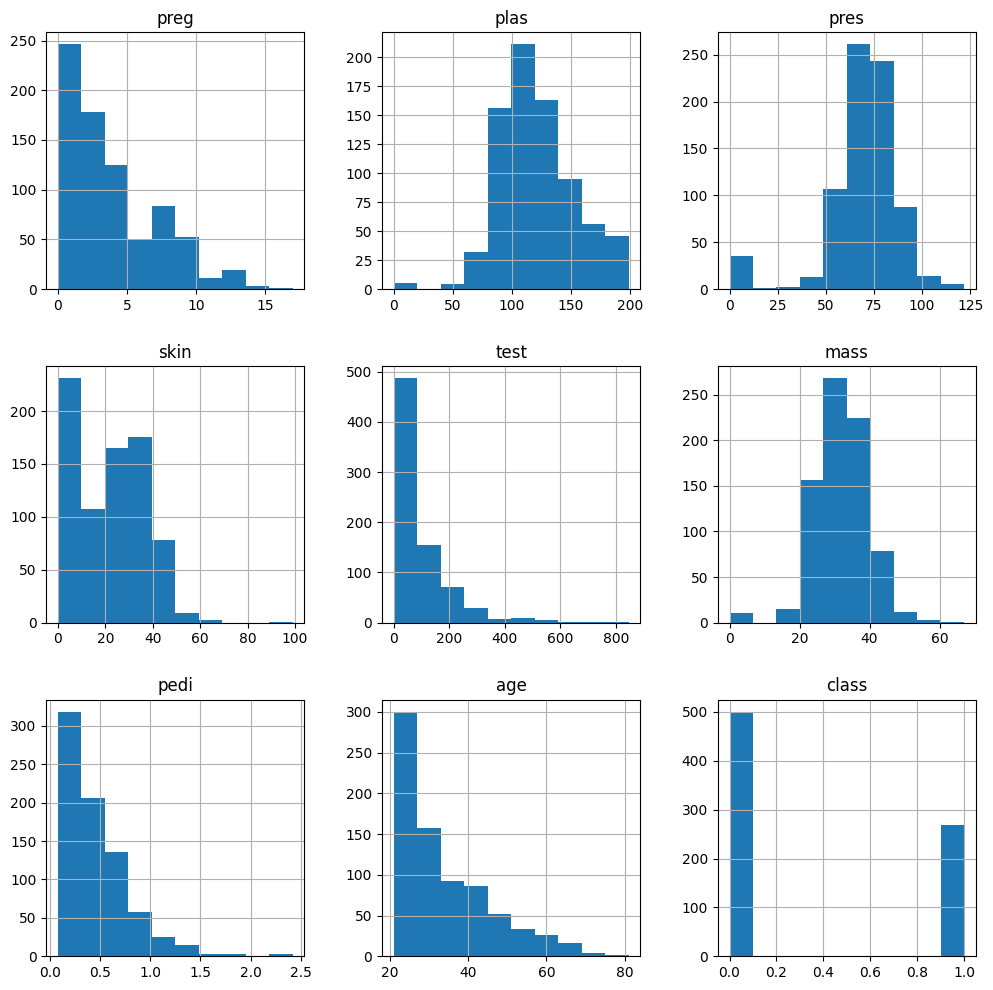

In [3]:
pyplot.rcParams["figure.figsize"] = [12,12]
data.hist()
pyplot.show()

---

### <font color=red>Exercise 1</font>

Compare what you see here, with what you saw as non-viz data exploration in the previous notebook. Where are you most familiar? The first, the second, or by using both?

Do you have additional observations from these plots, that you did not make over textual descriptive statistics? Hint: which histograms look roughly Gaussian and which are skewed?

---

### Density plots

In [4]:
#from matplotlib import pyplot

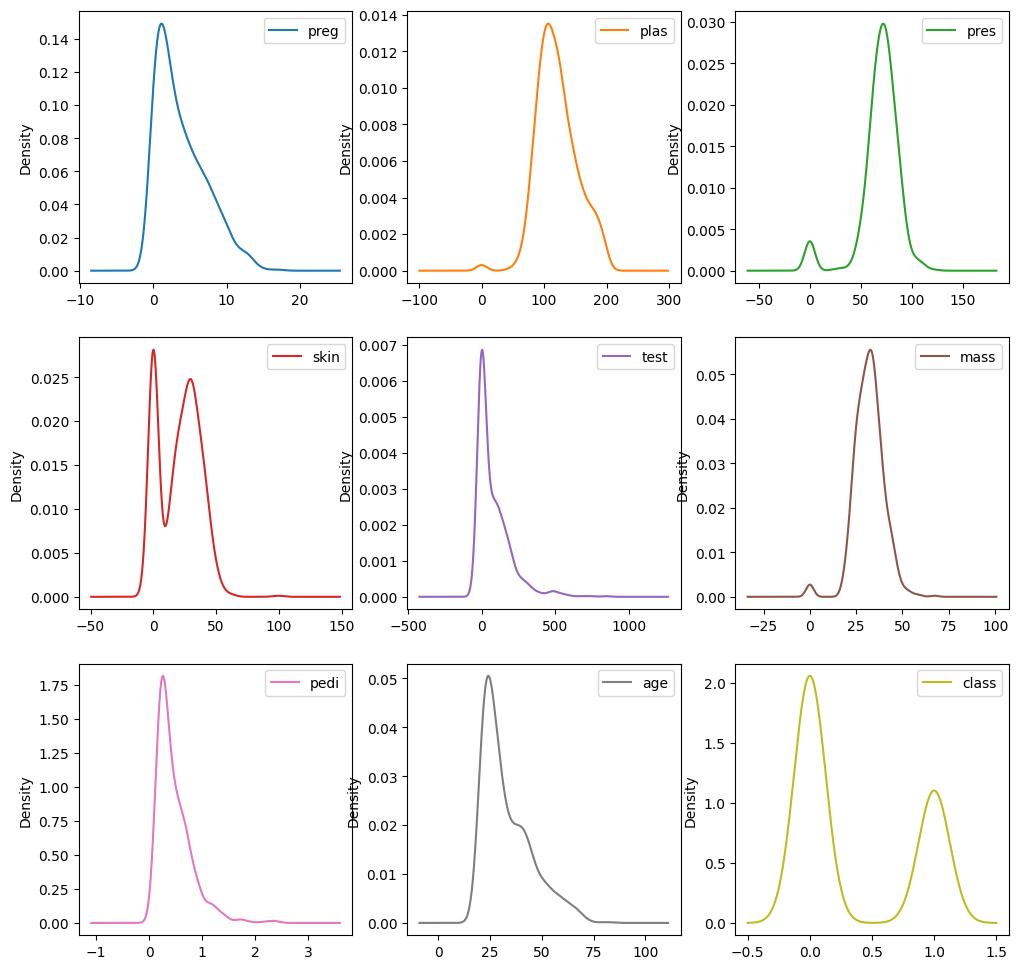

In [5]:
data.plot(kind='density', subplots=True, layout=(3,3), sharex=False)
pyplot.show()

### Box and Whisker plots

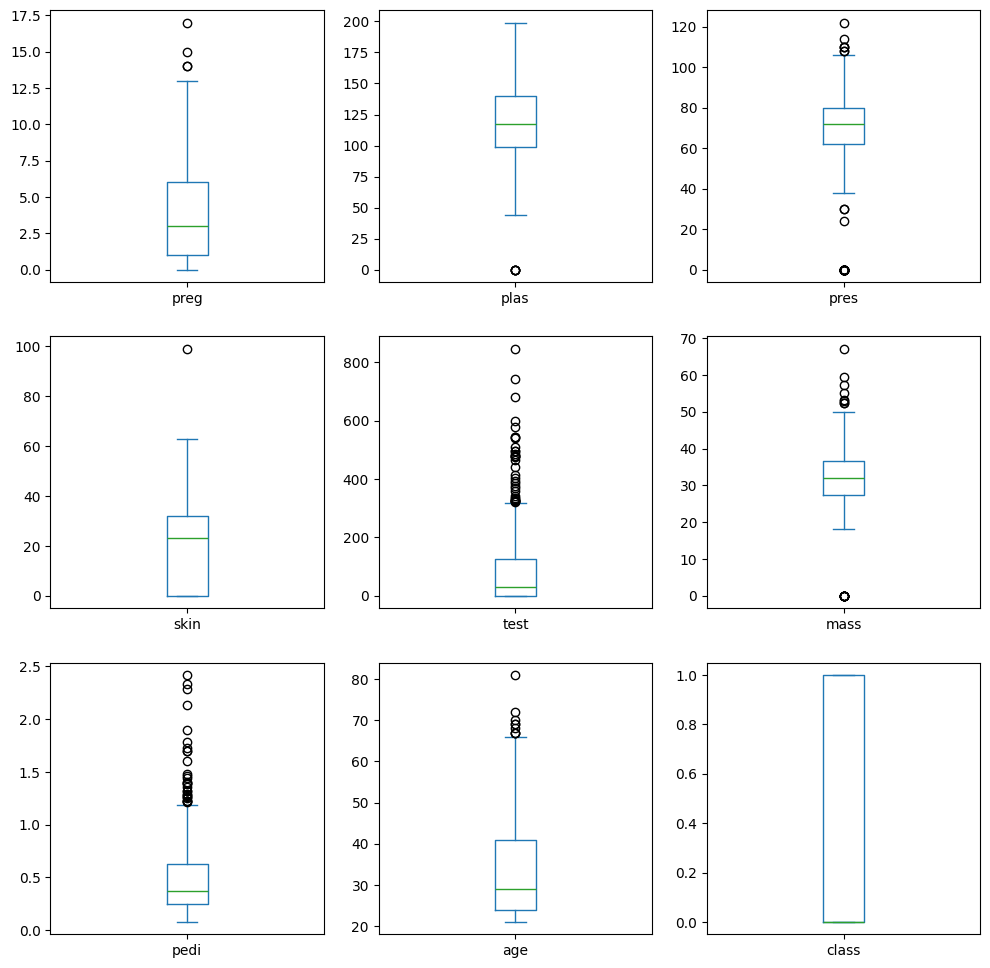

In [6]:
data.plot(kind='box', subplots=True, layout=(3,3), sharex=False, sharey=False)
pyplot.show()

In [7]:
### upload -> BoxAndWhiskers.png
from google.colab import files
uploaded = files.upload()

Saving BoxAndWhiskers.png to BoxAndWhiskers.png


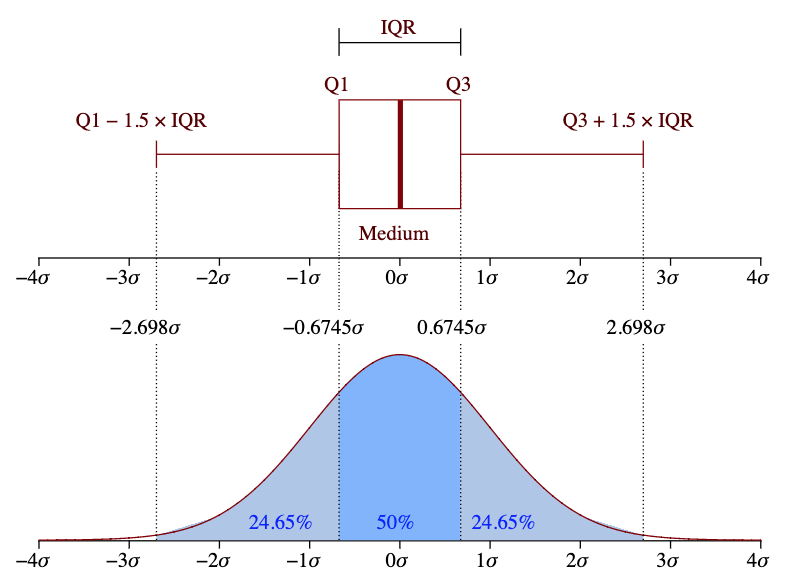

In [8]:
from IPython.display import Image
Image(filename='/content/BoxAndWhiskers.png')

NOTE: Have you notices that the 0 placeholders from the previous notebook often show up as outliers? **Visual investigation helps**!

**But..** if they are plenty (e.g. `test`) they look as "good" ones.. **Never rely on one source of input for your reasoning: always cross-check as mush as possible**!

A brief discussion on `test`. This is the 2-hour serum insulin measurement, and a living person can't have zero insulin, so every 0 is a missing value recorded as 0. It is the most affected column, in this example: 374 of the 768 rows are 0, about 49%! This, as we discussed in the other notebook, is the strongest case in this example for considering the action of dropping the feature, rather than imputing it.

## Multivariate plots
They show the interactions between multiple variables in your dataset.

### Correlation matrix plots

In [9]:
#from matplotlib import pyplot
import numpy

In [10]:
correlations = data.corr()
correlations

,preg,plas,pres,skin,test,mass,pedi,age,class
preg,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
plas,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
pres,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
skin,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
test,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
mass,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
pedi,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
class,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


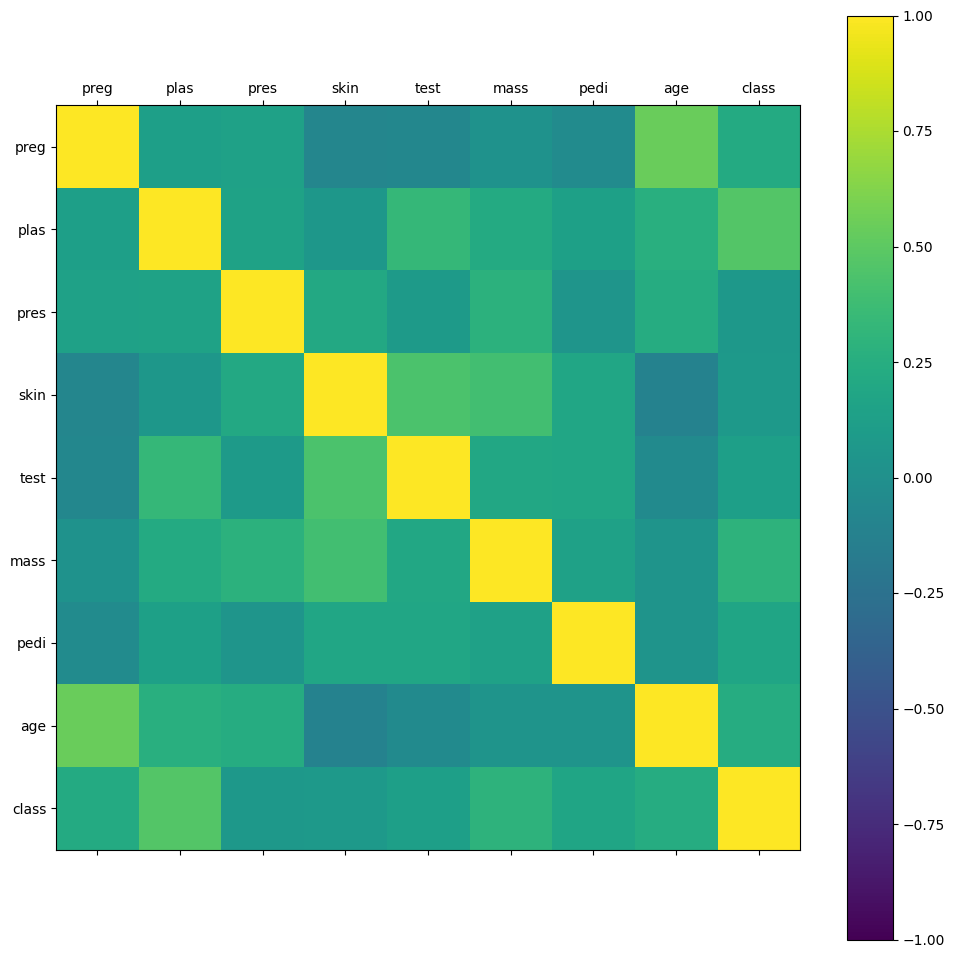

In [11]:
# plot correlation matrix
fig = pyplot.figure()
ax = fig.add_subplot(111)
cax = ax.matshow(correlations, vmin=-1, vmax=1)
fig.colorbar(cax)

# one tick per column, labels taken from the DataFrame itself
ticks = list(range(len(data.columns)))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(data.columns)
ax.set_yticklabels(data.columns)
pyplot.show()

Maybe:
*   choose more explanatory colors in the colormap;
*   display the correlation coefficients numerically

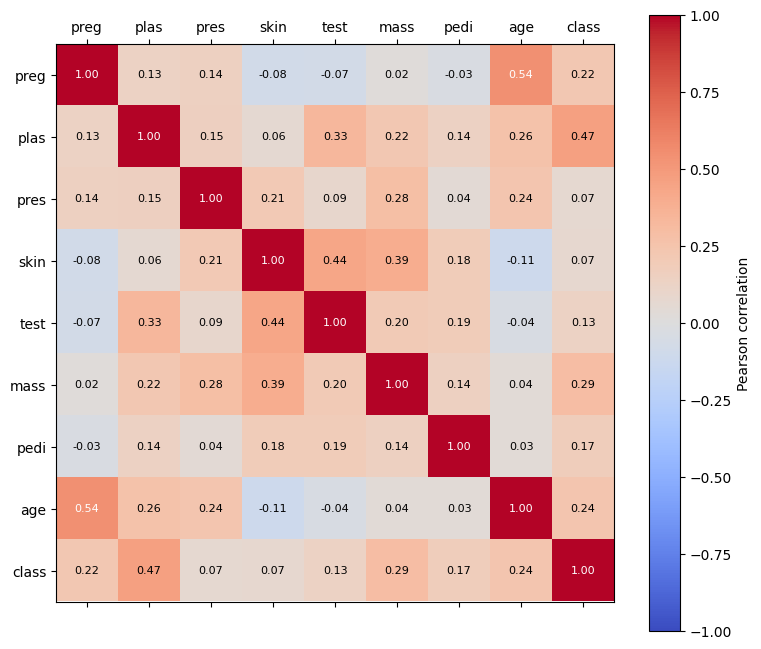

In [12]:
# plot correlation matrix
fig = pyplot.figure(figsize=(9, 8))
ax = fig.add_subplot(111)
#cax = ax.matshow(correlations, vmin=-1, vmax=1)
cax = ax.matshow(correlations, vmin=-1, vmax=1, cmap='coolwarm')
cbar = fig.colorbar(cax)
cbar.set_label('Pearson correlation')

ticks = list(range(len(data.columns)))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(data.columns)
ax.set_yticklabels(data.columns)

# write each correlation value in its cell
for i in range(len(correlations)):
    for j in range(len(correlations.columns)):
        value = correlations.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha='center', va='center', fontsize=8,
                color='white' if abs(value) > 0.5 else 'black')

pyplot.show()

Look at the correlation matrix above. Notice that it also includes `class`, our target, not only the eight input features.

1. Which features have the strongest correlation with `class`? Are these the ones you would expect?
2. Which pairs of features are strongly correlated with each other, for example `age` and `preg`? Why might that matter when we build a model?
3. Should `class` be part of a plot used to choose input features? Why or why not?

Train yourself: target relationships first, then redundancy between inputs, then the modelling implication.

### Answers below

1. Strongest correlations with `class`: `plas` (glucose) is the strongest, at roughly 0.47, followed by `mass` (BMI) and `age`, both weaker. This is what you would expect: glucose and BMI are established diabetes risk factors.

2. Strongly correlated feature pairs: `preg` and `age` are the clearest (roughly 0.54), because older women have had more pregnancies. `skin` and `mass` are also moderately correlated. Redundancy matters because two near-duplicate inputs make coefficients unstable and split importance scores.

3. Should `class` guide feature choice? Only within a proper procedure. Choosing features by looking at the full correlation matrix uses the target before any evaluation, which biases the results. The target is for measuring model performance, and any selection based on it should happen inside validation, as discussed in one of next notebooks.

## (when needed) re-assess your problem statement
This is probably a good time you ask yourself a question: ** did I understood and set up the research question properly?**. Do it any time needed, and defintely after a proper EDA.

If you do so, a question could be: _Is the dataset containing only women, perhaps?_ The answer will help to continue with a more focussed research question, and a better understanding of your problem.

The answer is **yes**! The dataset contains only women: all patients are native american females, of Pima Indian heritage, at least 21 years old, living near Phoenix, Arizona: the name "Pima" is an exonym as the people call themselves the Akimel O'odham ("River People") and related groups. This is documented in the original study data from the National Institute of Diabetes and Digestive and Kidney Diseases, which the Kaggle and UCI copies reproduce.

Does it help me to know? Yes, it has at least 3 consequences:

* The `preg` (pregnancies) feature only applies to women, of course, no equivalent for male patients, and there are none inthe dataset
* The sample is one specific population, so a model trained on it may not generalise to other ethnic groups, or to men! A data scientists should avoid presenting the results as general diabetes predictions!

Overall, I am way more deep into the problem, which is good!

Let's continue..



### Scatter plot matrix

In [13]:
from pandas.plotting import scatter_matrix

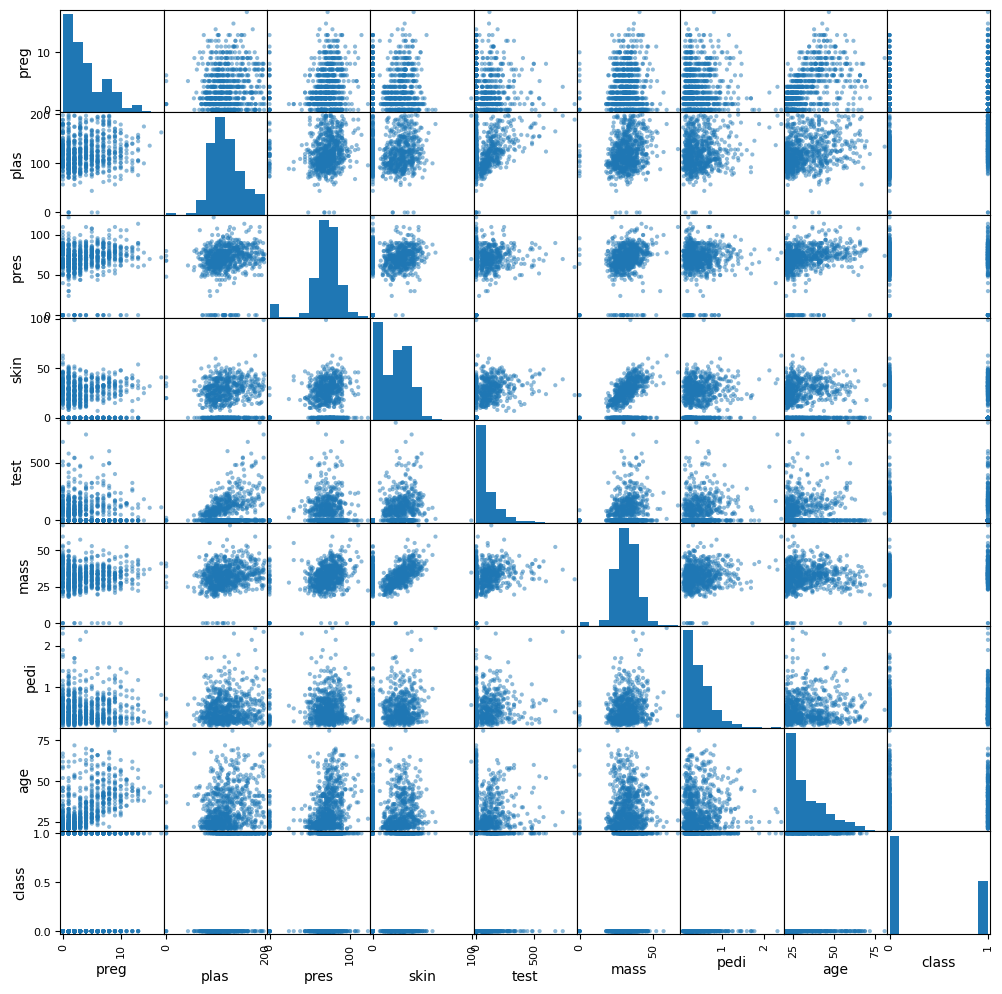

In [14]:
#scatter_matrix(data)
scatter_matrix(data, figsize=(12, 12), alpha=0.5)
pyplot.show()

### <font color=red>Exercise 2</font>

Do you spot something interesting in the data by visualizing it in this way?

This is the right time to discuss a bit about **feature correlations**.

The correlation matrix (both in numbers and in viz) shows how strongly pairs of features move together, and how each feature relates to the target `class`. But how is it counted? Pearson measures only linear relationships, so a weak value does not mean a feature is useless. Also, Pearson correlation is computed on the raw data, so e.g. the zeros in plas, pres, skin, test and mass distort the coefficients. Recompute the matrix after the zeros are handled, and treat any earlier conclusion as provisional.

In addition, high correlation *between features* (e.g. `skin` and `mass`) means they carry partly redundant information. It is not automatically a reason to drop one of the two, though. A correlation with `class` is what we want.

Consider that this aspet can impact models in different ways, dependingon the model. This can destabilise linear models and blur their coefficients, for example.
*   In linear models (e.g. logistic regression), correlated features make the individual coefficients unstable and hard to interpret. Small changes in the data can shift weight between the two features, and the standard errors inflate. Predictions are usually still fine, but “which feature matters” becomes unreliable.
*   Tree-based models: prediction is rarely hurt by correlated features. The problem is in importance scores: a tree can use either of two correlated features, so the importance gets split between them and each looks less important than it is.

So, before removing a feature, check whether the correlation is very high (say |r| > 0.9), whether the model actually needs it or benefits from it, and whether the correlation is distorted by any existing zero placeholders.

Feature selection is covered more in one of the next notebooks.



### <font color=red>Exercise 3</font>

Try to review previous and current notebooks, and think how to produce a new one of your own that would eventually digest all exploration-related tasks (both textually and visually), on a generic CSV file in input, in one shot. As a skeleton outline of a reusable EDA function:
1. input: a CSV path
2. steps: shape, dtypes, describe, class counts, correlations, skew, histograms, boxplots

Some hints:
* Stay clean
* Focus on instructions you need, avoid unnecessary ones
* be careful with heading levels (indentation)
* test it by trying `Runtime` -> `Run all` in the GUI menu

This is not wasted time: if you do it cleanly and usefully, you might end up in expand it further and re-use it often!

## Summary

What we did:

* **EDA** (exploratory data analysis) means analysing and understanding your dataset before building models.
* We used 5 quick ways to explore the dataset visually:
  1. **Histograms**: `data.hist()`, the distribution of each feature.
  2. **Density plots**: `data.plot(kind='density')`, a smoothed view of each distribution.
  3. **Box and whisker plots**: `data.plot(kind='box')`, the median, spread and outliers of each feature.
  4. **Correlation matrix**: `data.corr()` shown with `matshow`, the pairwise linear relationships.
  5. **Scatter plot matrix**: `scatter_matrix(data)`, pairwise scatter plots with histograms on the diagonal.
* Each of these would have taken considerable time to produce in a basic plotting system. Pandas and matplotlib make them one line each.

## What's next

Let's start to manipulate the data: we need to prepare the data to best expose the structure of your problem to modeling algorithms.